# Network Resilience Analyzer

**Intermediate ITW III course project**  
Analyze a communication network, identify critical nodes, and compare the effect of random failures with targeted node removal.

**Libraries:** NetworkX and Matplotlib. The network is defined in this notebook, so no external files or internet access are needed.

> Run cells from top to bottom. The analysis is an educational simulation; it does not represent a live network.


In [1]:
import random
import statistics
import networkx as nx
import matplotlib.pyplot as plt

SEED = 17
random.seed(SEED)
plt.rcParams.update({"figure.figsize": (8, 5), "figure.dpi": 120, "font.size": 10})


## 1. Problem and network model
A network can continue operating after some devices fail, but a few highly connected or strategically placed devices may be critical. We represent devices as nodes and communication links as undirected edges. The example topology is deliberately small enough to explain during a presentation while containing redundant paths and several bridge-like connections.

In [2]:
edges = [
    ("Gateway", "Router_A"), ("Gateway", "Router_B"),
    ("Router_A", "Router_B"), ("Router_A", "Switch_1"),
    ("Router_B", "Switch_2"), ("Switch_1", "Switch_2"),
    ("Switch_1", "Server_1"), ("Switch_1", "Lab_PC_1"),
    ("Switch_1", "Lab_PC_2"), ("Switch_2", "Server_2"),
    ("Switch_2", "Office_PC_1"), ("Switch_2", "Office_PC_2"),
    ("Server_1", "Server_2"), ("Router_B", "WiFi_AP"),
    ("WiFi_AP", "Student_1"), ("WiFi_AP", "Student_2"),
    ("Student_1", "Student_2"),
]
G = nx.Graph()
G.add_edges_from(edges)
print(f"Devices: {G.number_of_nodes()} | Links: {G.number_of_edges()}")
print(f"Connected: {nx.is_connected(G)} | Density: {nx.density(G):.3f}")
print("Average shortest-path length:", round(nx.average_shortest_path_length(G), 2))


Devices: 14 | Links: 17
Connected: True | Density: 0.187
Average shortest-path length: 2.58


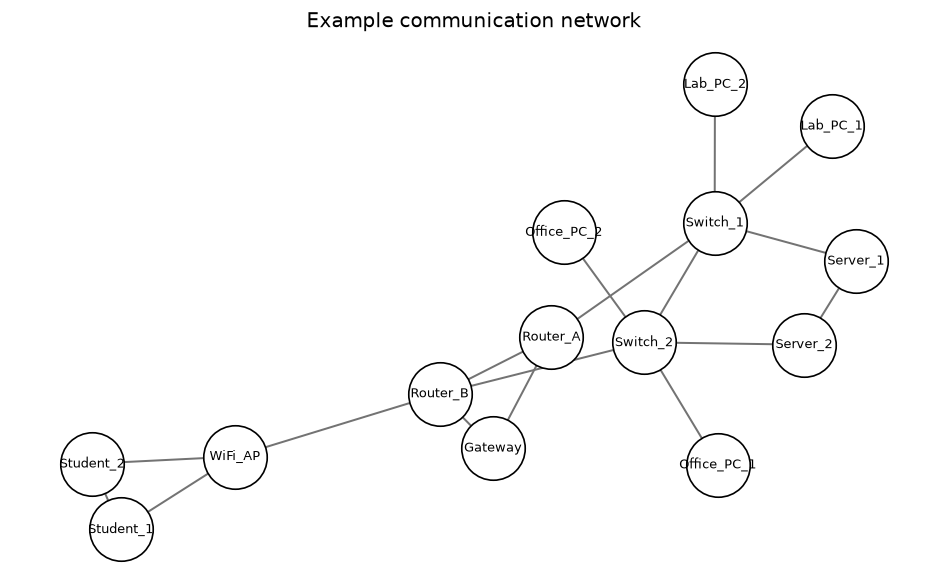

In [3]:
pos = nx.spring_layout(G, seed=SEED)
plt.figure()
nx.draw_networkx(G, pos, node_color="white", edgecolors="black",
                 edge_color="0.45", node_size=1450, width=1.2, font_size=8)
plt.title("Example communication network")
plt.axis("off")
plt.tight_layout()
plt.show()


## 2. Find important devices
Degree centrality measures the share of devices directly connected to a node. Betweenness centrality estimates how often a node lies on shortest routes between other pairs. These are useful clues, but they do not by themselves prove that a real device is operationally critical.

In [4]:
degree = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(G)
ranked = sorted(G.nodes, key=lambda n: (betweenness[n], degree[n]), reverse=True)
print(f"{'Device':<15} {'Degree':>8} {'Betweenness':>13}")
for n in ranked:
    print(f"{n:<15} {degree[n]:>8.3f} {betweenness[n]:>13.3f}")


Device            Degree   Betweenness
Switch_2           0.385         0.498
Router_B           0.308         0.459
Switch_1           0.385         0.402
WiFi_AP            0.231         0.282
Router_A           0.231         0.145
Server_2           0.154         0.036
Server_1           0.154         0.024
Gateway            0.154         0.000
Student_1          0.154         0.000
Student_2          0.154         0.000
Lab_PC_1           0.077         0.000
Lab_PC_2           0.077         0.000
Office_PC_1        0.077         0.000
Office_PC_2        0.077         0.000


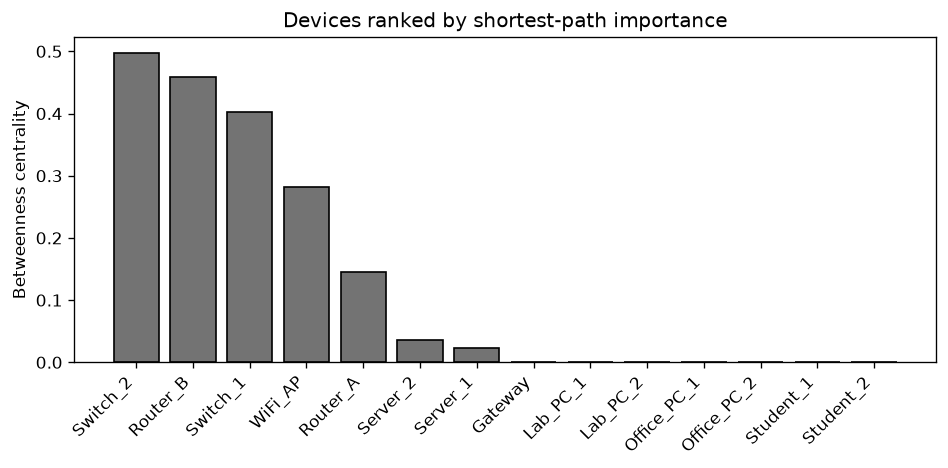

In [5]:
ordered = sorted(G.nodes, key=lambda n: betweenness[n], reverse=True)
plt.figure(figsize=(8, 4))
plt.bar(ordered, [betweenness[n] for n in ordered], color="0.45", edgecolor="black")
plt.ylabel("Betweenness centrality")
plt.title("Devices ranked by shortest-path importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 3. Failure and attack simulation
For each removal percentage, the random strategy removes a randomly selected subset of devices. The targeted strategy removes devices in descending betweenness order, computed from the original network. The outcome is the fraction of original device pairs that remain mutually reachable. We average the random outcome over 200 trials per percentage. The targeted strategy is a simple static attack model, not a changing re-ranking attack.

In [6]:
def reachable_pair_fraction(graph, original_nodes):
    """Fraction of all original unordered device pairs still connected."""
    total_pairs = len(original_nodes) * (len(original_nodes) - 1) / 2
    remaining = [n for n in original_nodes if n in graph]
    reachable = sum(len(c) * (len(c) - 1) / 2 for c in nx.connected_components(graph))
    return reachable / total_pairs if total_pairs else 0.0

def removal_curve(graph, fractions, strategy, trials=200, seed=SEED):
    nodes = list(graph.nodes)
    rng = random.Random(seed)
    curve = []
    for fraction in fractions:
        k = round(fraction * len(nodes))
        if strategy == "targeted":
            removal_sets = [sorted(nodes, key=lambda n: betweenness[n], reverse=True)[:k]]
        else:
            removal_sets = [rng.sample(nodes, k) for _ in range(trials)]
        scores = []
        for removed in removal_sets:
            remaining_graph = graph.copy()
            remaining_graph.remove_nodes_from(removed)
            scores.append(reachable_pair_fraction(remaining_graph, nodes))
        curve.append(statistics.mean(scores))
    return curve

fractions = [i / 10 for i in range(0, 9)]
random_scores = removal_curve(G, fractions, "random")
targeted_scores = removal_curve(G, fractions, "targeted")
for f, r, t in zip(fractions, random_scores, targeted_scores):
    print(f"Removed {f:>3.0%}: random={r:.3f}, targeted={t:.3f}")


Removed  0%: random=1.000, targeted=1.000
Removed 10%: random=0.779, targeted=0.604
Removed 20%: random=0.440, targeted=0.055
Removed 30%: random=0.316, targeted=0.033
Removed 40%: random=0.135, targeted=0.011
Removed 50%: random=0.093, targeted=0.011
Removed 60%: random=0.059, targeted=0.011
Removed 70%: random=0.018, targeted=0.011
Removed 80%: random=0.009, targeted=0.011


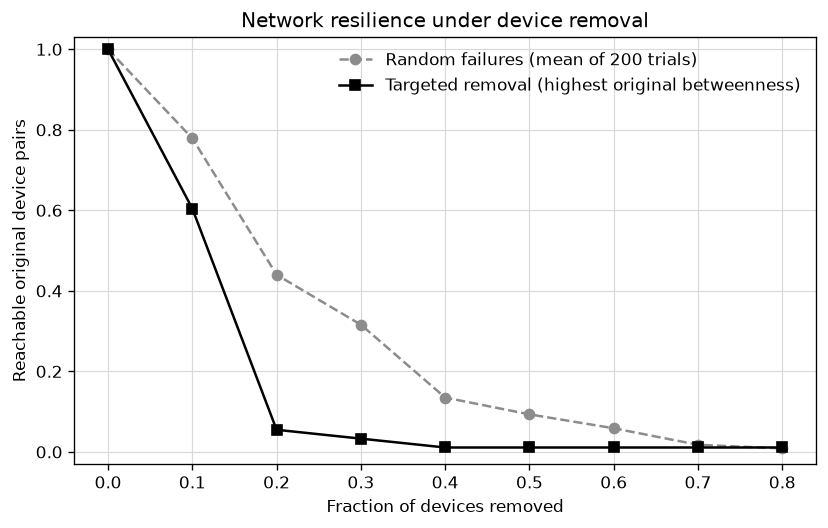

In [7]:
plt.figure(figsize=(7, 4.5))
plt.plot(fractions, random_scores, marker="o", color="0.55",
         linestyle="--", label="Random failures (mean of 200 trials)")
plt.plot(fractions, targeted_scores, marker="s", color="black",
         label="Targeted removal (highest original betweenness)")
plt.xlabel("Fraction of devices removed")
plt.ylabel("Reachable original device pairs")
plt.ylim(-0.03, 1.03)
plt.title("Network resilience under device removal")
plt.grid(True, color="0.85", linewidth=0.7)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


## 4. Interpretation and limitations
The curves show how much pairwise reachability remains under each removal strategy. In this topology, removing a highly central device can fragment the network sooner than removing an arbitrary device, illustrating why redundancy around critical infrastructure matters. The exact values depend on this small hand-built topology and the chosen metric. The model assumes undirected links, equal importance for every device pair, and instantaneous device removal; it omits link failures, capacity, traffic demand, recovery, and real-world routing protocols.

### Conclusion
NetworkX makes it practical to model a network and inspect connectivity, shortest paths, and centrality. The experiment demonstrates a reproducible way to compare failure scenarios and identify where additional redundant links may improve resilience. A next step would be to model link failures or re-rank centrality after each targeted removal.